# Emg3d pyGIMLI inversion testing in 3-dimensions

Requires
- `pygimli>=1.5.2`
- ipygimli.py

v8: try to invert for a box-like hot plume, with minimal noise, with 10 sources from the original survey design & inverting for the whole area around the plume

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

import emg3d
import ipygimli as ipygimli
from Emg3d_extra_grid_functions_v26 import *
import pandas as pd
import h5py

In [2]:
#Random number regenerator used to set the noise, seed guarantees the same noise is reproduced each time, can be adapted with different numbers to test different noise
rng_real = np.random.default_rng(seed=0)
rng_imag = np.random.default_rng(seed=1)

## Create synthetic data

Model used in previous forward-modeling (v1), with a cuboid hot plume inside

### Define survey and baseline resistivity model

In [3]:
# Source, y-directed point dipole on the surface
src_coords = [(0, -126, 0, 90.0, 0.0),
              (0, -25, 0, 90.0, 0.0),
              (0, 25, 0, 90.0, 0.0),
              (0, 100, 0, 90.0, 0.0),
              (-75, -50, 0, 0.0, 0.0),
              (-75, 50, 0, 0.0, 0.0),
              (-25, 50, 0, 0.0, 0.0),
              (25, 50, 0, 0.0, 0.0),
              (75, -50, 0, 0.0, 0.0),
              (75, 50, 0, 0.0, 0.0)]
src = []
for src_coord in src_coords:
    src.append(emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coord))

# Source frequency
frequency = 1

# Receivers, vertical z-directed point dipoles
rec_x = np.arange(1, 41)*0
rec_y = np.array([75]*40)
rec_z = np.arange(1,41)*-7.5
rec_coords = (rec_x, rec_y, rec_z, 0.0, 90.0)
rec = emg3d.surveys.txrx_coordinates_to_dict(emg3d.RxElectricPoint, rec_coords)

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)

In [4]:
# For empymod

# Receiver offsets
offsets = np.arange(0, 300, 7.5)  # 300 m long receiver line

# receiver-array: x, y, z, azimuth, dip
receivers = (offsets*0, [75]*len(offsets), -offsets, 0, 90)  # z-directed, Ez response

In [5]:
# define the input that stays the same for all models
inp = {
    'src': src,
    'rec': rec,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

### Create grids

In [6]:
cgrid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-140, 100], [-300, 25]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [15, 15, 5],
)
 
cgrid # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 524,288 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     64   -102,353.92    102,353.92     15.00 26,438.88    1.35
   y     64   -102,493.09    142,269.02     15.00 39,820.93    1.39
   z    128   -108,798.04    143,051.73      5.00 34,528.69    1.32

In [7]:
#Insert baseline resistivity values into the coarse grid

# Pre-allocate an array with number of cells corresponding to our grid
cres_base = np.ones(cgrid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    cres_base[:, :, (cgrid.cell_centers_z > dd[i+1]) & (cgrid.cell_centers_z <= dd[i])] = resistivities_base[i]

cmodel_base = emg3d.Model(cgrid, property_x=cres_base, mapping='Resistivity')
cmodel_base_sigma = emg3d.Model(cgrid, property_x=1/np.array(cres_base), mapping='Conductivity')

In [8]:
fgrid = emg3d.construct_mesh(
    center=(0,-135,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-140, 100], [-300, 25]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [5, 5, 2.5],
)
 
fgrid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 1,769,472 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     96   -100,983.68    100,983.68      5.00 26,632.29    1.36
   y     96   -102,596.20    102,556.20      5.00 31,281.10    1.44
   z    192   -102,815.47    102,540.47      2.50 26,495.26    1.35

In [9]:
#Insert baseline resistivity values into the fine grid

# Pre-allocate an array with number of cells corresponding to our grid
fres_base = np.ones(fgrid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    fres_base[:, :, (fgrid.cell_centers_z > dd[i+1]) & (fgrid.cell_centers_z <= dd[i])] = resistivities_base[i]

fmodel_base = emg3d.Model(fgrid, property_x=fres_base, mapping='Resistivity')
fmodel_base_sigma = emg3d.Model(fgrid, property_x=1/np.array(fres_base), mapping='Conductivity')

### True model definition
We insert a box-like "cuboid" hot plume into both grids and QC that they are the same

In [10]:
cres_target = change_grid_values(cres_base, cgrid, 50, 50, -190, -120, 13)
fres_target = change_grid_values(fres_base, fgrid, 50, 50, -190, -120, 13)

[-49, -49, -189] [49, 49, -121]
x:  -52.50000000000777
y:  -52.499999999999545
z:  -187.49999999999397
x:  52.49999999999223
y:  52.500000000000455
z:  -122.49999999999397
x bounds:  -52.50000000000777  ,  52.49999999999223
y_bounds:  -52.499999999999545  ,  52.500000000000455
z_bounds:  -187.49999999999397  ,  -122.49999999999397
[-49, -49, -189] [49, 49, -121]
x:  -47.50000000000226
y:  -47.49999999998795
z:  -188.75000000000034
x:  47.49999999999774
y:  47.50000000001205
z:  -121.25000000000034
x bounds:  -47.50000000000226  ,  47.49999999999774
y_bounds:  -47.49999999998795  ,  47.50000000001205
z_bounds:  -188.75000000000034  ,  -121.25000000000034


In [11]:
cmodel_target = emg3d.Model(cgrid, property_x=cres_target, mapping='Resistivity')
fmodel_target = emg3d.Model(fgrid, property_x=fres_target, mapping='Resistivity')
cmodel_target_sigma = emg3d.Model(cgrid, property_x=1/np.array(cres_target), mapping='Conductivity')
fmodel_target_sigma = emg3d.Model(fgrid, property_x=1/np.array(fres_target), mapping='Conductivity')

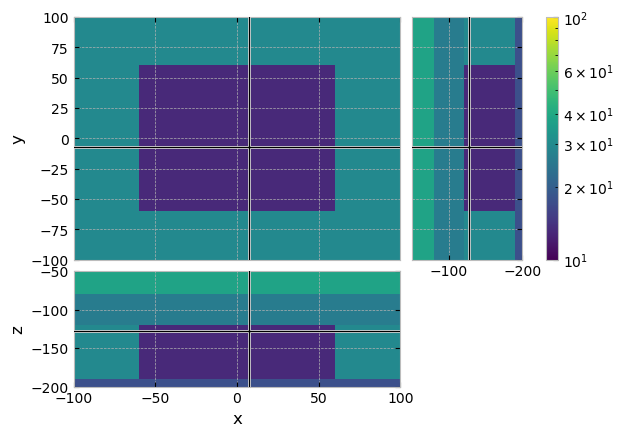

In [12]:
#QC cube location
cgrid.plot_3d_slicer(
    cmodel_target.property_x,
    pcolor_opts={'norm': LogNorm(vmin=1e1, vmax=1e2)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -50],
    zslice=-125,
)
fig = plt.gcf()

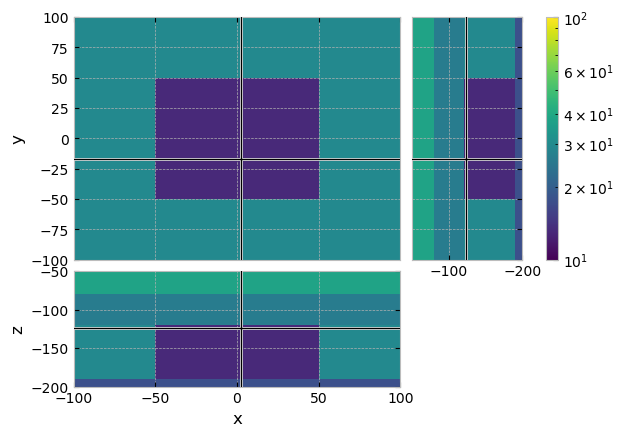

In [13]:
#QC cube location
fgrid.plot_3d_slicer(
    fmodel_target.property_x,
    pcolor_opts={'norm': LogNorm(vmin=1e1, vmax=1e2)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -50],
    zslice=-125,
)
fig = plt.gcf()

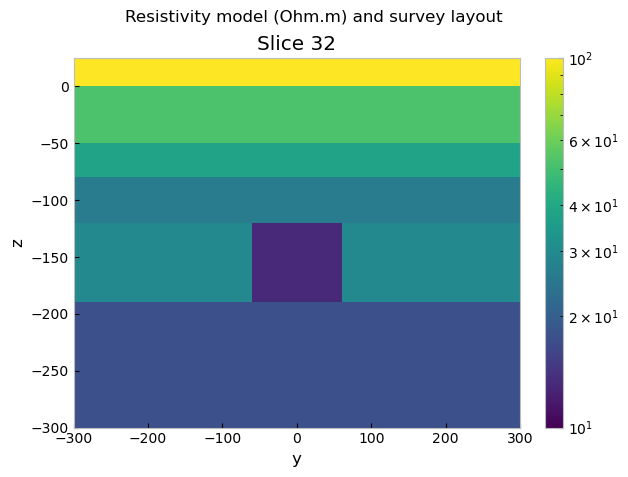

In [14]:
#Focus on the y,z plane
f0 = cgrid.plot_slice(
    cmodel_target.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

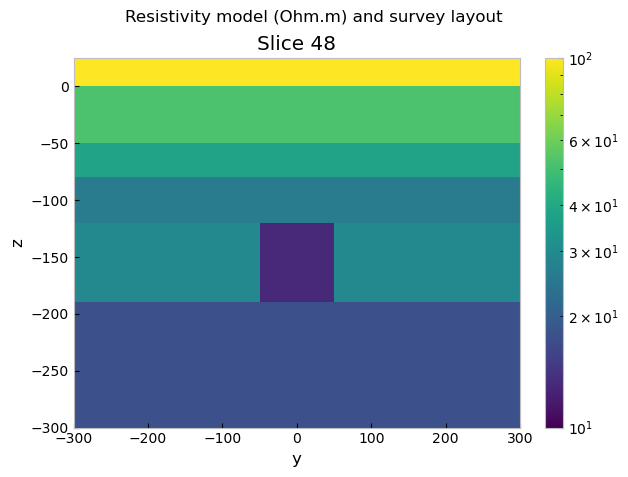

In [15]:
#Focus on the y,z plane
f0 = fgrid.plot_slice(
    fmodel_target.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

### Test numerical errors

We check the numerical error and also the source field for different sources

In [16]:
# define the input that stays the same for all models
inp = {
    'src': src,
    'rec': receivers,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

In [17]:
empymod_base_list = []

for i in np.arange(len(src_coords)):
    inp['src'] = src_coords[i]
    empymod_base_list.append(empymod.bipole(res=resistivities_base, **inp))

#### Test source footprints

In [18]:
#Generate source field

c_source_field_list = []
f_source_field_list = []
for i in np.arange(len(src_coords)):
    source = src_coords[i]
    c_source_field_list.append(emg3d.fields.get_source_field(cgrid, source=source, frequency=frequency))
    f_source_field_list.append(emg3d.fields.get_source_field(fgrid, source=source, frequency=frequency))

In [72]:
print(src_coords[1])

(0, -25, 0, 90.0, 0.0)


Text(0.5, 0.98, 'Ey field for source 0')

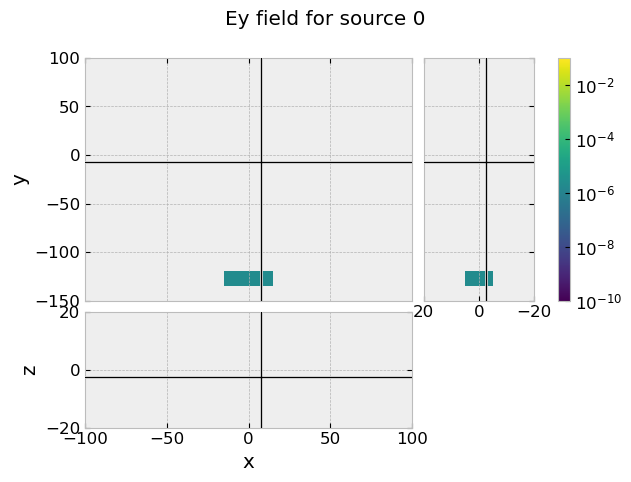

In [91]:
field = c_source_field_list[0]

#QC cube location
cgrid.plot_3d_slicer(
    field.fy.ravel('F'),
    view='abs',
    v_type='Ey',
    pcolor_opts={'norm': LogNorm(vmin=1e-10, vmax=1e-1)},
    xlim=[-100, 100],
    ylim=[-150, 100],
    zlim=[-20, 20],
    zslice=0,
)
fig = plt.gcf()
fig.suptitle('Ey field for source 0')

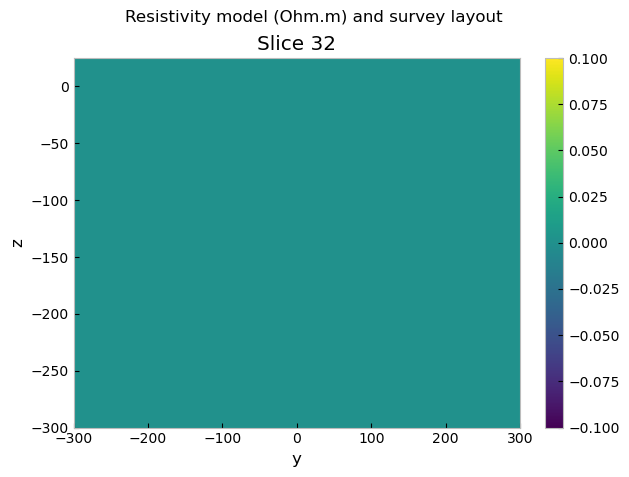

In [ ]:
field = c_source_field_list[0]

#Focus on the y,z plane
f0 = cgrid.plot_slice(
    field.fz.ravel('F'),
    view='abs',
    v_type='Ez',
    normal = 'X',
    #pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

#### Testing numerical error against empymod for the baseline

In [22]:
# Baseline model

c_emg3d_field_base_list = []
f_emg3d_field_base_list = []
for i in np.arange(len(src_coords)):
    c_sfield = c_source_field_list[i]
    f_sfield = f_source_field_list[i]
    c_emg3d_field_base_list.append(emg3d.solve(cmodel_base, c_sfield, verb=2))
    f_emg3d_field_base_list.append(emg3d.solve(fmodel_base, f_sfield, verb=2))

:: emg3d :: 6.7e-07; 3(18); 0:03:31; CONVERGED
:: emg3d :: 5.9e-06; 5(33); 1:17:50; CONVERGED
:: emg3d :: 8.2e-07; 2(15); 0:05:10; CONVERGED
:: emg3d :: 4.8e-07; 6(33); 0:38:57; CONVERGED
:: emg3d :: 8.4e-07; 3(17); 0:05:51; CONVERGED
:: emg3d :: 9.2e-07; 6(34); 0:40:41; CONVERGED
:: emg3d :: 6.5e-07; 4(20); 0:07:01; CONVERGED
:: emg3d :: 4.3e-07; 6(34); 0:41:35; CONVERGED
:: emg3d :: 5.2e-07; 4(20); 0:07:11; CONVERGED
:: emg3d :: 4.4e-07; 6(32); 12:42:14; CONVERGED
:: emg3d :: 5.6e-07; 4(20); 0:04:29; CONVERGED
:: emg3d :: 4.3e-07; 6(32); 0:27:00; CONVERGED
:: emg3d :: 4.9e-07; 3(19); 0:05:31; CONVERGED
:: emg3d :: 6.8e-04; 3(21); 0:18:27; STAGNATED (returned field is zero)
:: emg3d :: 5.3e-07; 3(19); 0:05:06; CONVERGED
:: emg3d :: 8.1e-04; 3(21); 0:18:54; STAGNATED (returned field is zero)
:: emg3d :: 5.3e-07; 4(20); 0:05:09; CONVERGED
:: emg3d :: 4.6e-07; 6(32); 0:27:39; CONVERGED
:: emg3d :: 5.8e-07; 4(20); 0:04:53; CONVERGED
:: emg3d :: 4.6e-07; 6(32); 0:28:44; CONVERGED


In [110]:
print(src_coords[7])

(25, 50, 0, 0.0, 0.0)


In [93]:
# Get receiver line response

c_emg3d_line_base_list = []
f_emg3d_line_base_list = []
for i in np.arange(len(src_coords)):
    c_efield = c_emg3d_field_base_list[i]
    f_efield = f_emg3d_field_base_list[i]
    c_emg3d_line_base_list.append(c_efield.get_receiver(receivers, 'linear'))
    f_emg3d_line_base_list.append(f_efield.get_receiver(receivers, 'linear'))

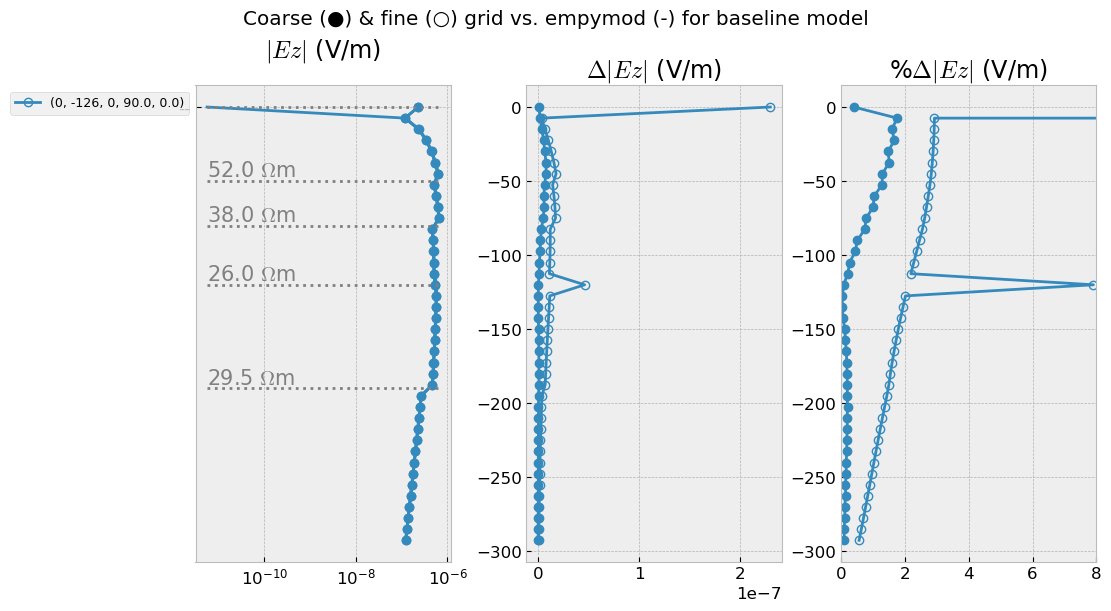

In [123]:
# Plot differences only

src_nrs = np.arange(len(src_coords))[:1]

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

fig3.suptitle("Coarse (●) & fine (○) grid vs. empymod (-) for baseline model")
plt.rcParams["font.size"] = 12

ax31.set_title('$|Ez|$ (V/m)')
ax32.set_title('$\\Delta |Ez|$ (V/m)')
ax33.set_title('%$\\Delta |Ez|$ (V/m)')

for src_nr in src_nrs:

    c_base = c_emg3d_line_base_list[src_nr] #coarse
    f_base = f_emg3d_line_base_list[src_nr] #fine
    a_base = empymod_base_list[src_nr] #analytic

    ax31.plot(c_base.amp(), -offsets, 'C'+str(src_nr), marker='o', fillstyle= 'full', linewidth=2)
    ax31.plot(f_base.amp(), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length
    ax31.plot(a_base.amp(), -offsets, 'C'+str(src_nr), '--', linewidth=2) # scale your emg3d amplitues by the source length
        
    ax32.plot(np.abs(c_base.amp()-f_base.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='full', linewidth=2)
    ax32.plot(np.abs(f_base.amp()-a_base.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)

    ax33.plot(100*np.abs((c_base.amp()-f_base.amp())/f_base.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='full', linewidth=2)
    ax33.plot(100*np.abs((f_base.amp()-a_base.amp())/a_base.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 8])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

#### Testing numerical error when including the target

In [ ]:
# Target model

c_emg3d_field_target_list = []
f_emg3d_field_target_list = []
for i in np.arange(len(src_coords)):
    c_sfield = c_source_field_list[i]
    f_sfield = f_source_field_list[i]
    c_emg3d_field_target_list.append(emg3d.solve(cmodel_target, c_sfield, verb=2))
    f_emg3d_field_target_list.append(emg3d.solve(fmodel_target, f_sfield, verb=2))

:: emg3d :: 7.5e-07; 3(18); 0:03:16; CONVERGED


In [ ]:
# Get receiver line response

c_emg3d_line_target_list = []
f_emg3d_line_target_list = []
for i in np.arange(len(src_coords)):
    c_efield = c_emg3d_field_target_list[i]
    f_efield = f_emg3d_field_target_list[i]
    c_emg3d_line_target_list.append(c_efield.get_receiver(receivers, 'linear'))
    f_emg3d_line_target_list.append(f_efield.get_receiver(receivers, 'linear'))

In [ ]:
# Plot differences only

src_nrs = np.arange(len(src_coords))[4:]

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

fig3.suptitle("Coarse (○) vs. fine (-) for target model")
plt.rcParams["font.size"] = 12

ax31.set_title('$|Ez|$ (V/m)')
ax32.set_title('$\\Delta |Ez|$ (V/m)')
ax33.set_title('%$\\Delta |Ez|$ (V/m)')

for src_nr in src_nrs:

    c_tar = c_emg3d_line_target_list[src_nr] #coarse
    f_tar = f_emg3d_line_target_list[src_nr] #fine

    ax31.plot(c_tar.amp(), -offsets, 'C'+str(src_nr), marker='o', fillstyle= 'none', linewidth=2)
    ax31.plot(f_tar.amp(), -offsets, 'C'+str(src_nr), '--', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length
        
    ax32.plot(np.abs(c_tar.amp()-f_tar.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)

    ax33.plot(100*np.abs((c_tar.amp()-f_tar.amp())/f_tar.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 100])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

#### Testing the numerical error of emg3d-created grids

We do this starting with the baseline model only as this already doesn't work

In [54]:
#Generate frequency- and source-dependent grids
gopts = {
    'properties': [25, 1e8],
    'min_width_limits': [5, 5, 2.5],
    #'stretching': (None, None, [1.0, 1.5]),
    'domain': (
        [-100, 100],
        [-100, 100],
        [-300, 25]
    ),
    'center_on_edge': True,
}

In [55]:
#From the source code of emg3d

# elif self.gridding == 'both':
#            # Get grid and store it.
#            center = self.survey.sources[source].center
#            inp = {**self.gridding_opts, 'frequency':
#                   self.survey.frequencies[freq], 'center': center}
#            self._dict_grid[source][freq] = meshes.construct_mesh(**inp)

In [56]:
#grids = []
#for i in np.arange(len(src_coords)):
#    grids.append(emg3d.meshes.construct_mesh(**gridding_opts, 'frequency': frequency, 'center': survey.sources[i].center))

In [57]:
#We don't include noise yet as we compute it ourselves later

survey = emg3d.surveys.Survey(
    name='Survey forward-modelling',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)

In [58]:
# Simulate with the true model to create the observed data free of noise

simulation = emg3d.simulations.Simulation(
            name='Simulation forward-modelling',    # A name for this simulation
            survey=survey,        # Our survey instance
            model=fmodel_base_sigma,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear" #Needed for correct computation of the gradient
        )

simulation.compute(observed=True)
#The simulation should now contain observed data (+noise), synthetic data (without noise) and standard deviation values
#The survey class is also updated with this information

Compute efields            0/10  [00:00]

In [59]:
#We don't include noise yet as we compute it ourselves later

survey2 = emg3d.surveys.Survey(
    name='Survey forward-modelling 2',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)

In [60]:
# Simulate with the true model to create the observed data free of noise

simulation2 = emg3d.simulations.Simulation(
            name='Simulation forward-modelling 2',    # A name for this simulation
            survey=survey,        # Our survey instance
            model=cmodel_base_sigma,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear" #Needed for correct computation of the gradient
        )

simulation2.compute(observed=True)
#The simulation should now contain observed data (+noise), synthetic data (without noise) and standard deviation values
#The survey class is also updated with this information

Compute efields            0/10  [00:00]

In [36]:
print(simulation2.data.synthetic[0])

<xarray.DataArray 'synthetic' (rec: 40, freq: 1)> Size: 640B
array([[7.41917043e-23-2.21606069e-23j],
       [7.41910409e-23-2.21604088e-23j],
       [7.41903775e-23-2.21602106e-23j],
       [7.41897142e-23-2.21600125e-23j],
       [7.41890508e-23-2.21598143e-23j],
       [7.41883874e-23-2.21596162e-23j],
       [7.41877241e-23-2.21594181e-23j],
       [7.41870607e-23-2.21592199e-23j],
       [7.41863974e-23-2.21590218e-23j],
       [7.41857340e-23-2.21588236e-23j],
       [7.41850706e-23-2.21586255e-23j],
       [7.41844073e-23-2.21584273e-23j],
       [7.41837439e-23-2.21582292e-23j],
       [7.41830805e-23-2.21580310e-23j],
       [7.41824172e-23-2.21578329e-23j],
       [7.41817538e-23-2.21576347e-23j],
       [7.41810904e-23-2.21574366e-23j],
       [7.41804271e-23-2.21572384e-23j],
       [7.41797637e-23-2.21570403e-23j],
       [7.41791004e-23-2.21568422e-23j],
       [7.41784370e-23-2.21566440e-23j],
       [7.41777736e-23-2.21564459e-23j],
       [7.41771103e-23-2.21562477e-23

In [63]:
print(np.abs(1+3j), np.sqrt(1*1+3*3))

3.1622776601683795 3.1622776601683795


C:\Users\suzannevannoor\AppData\Local\Temp\ipykernel_48196\3876786754.py:32: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax32.set_xscale('log')


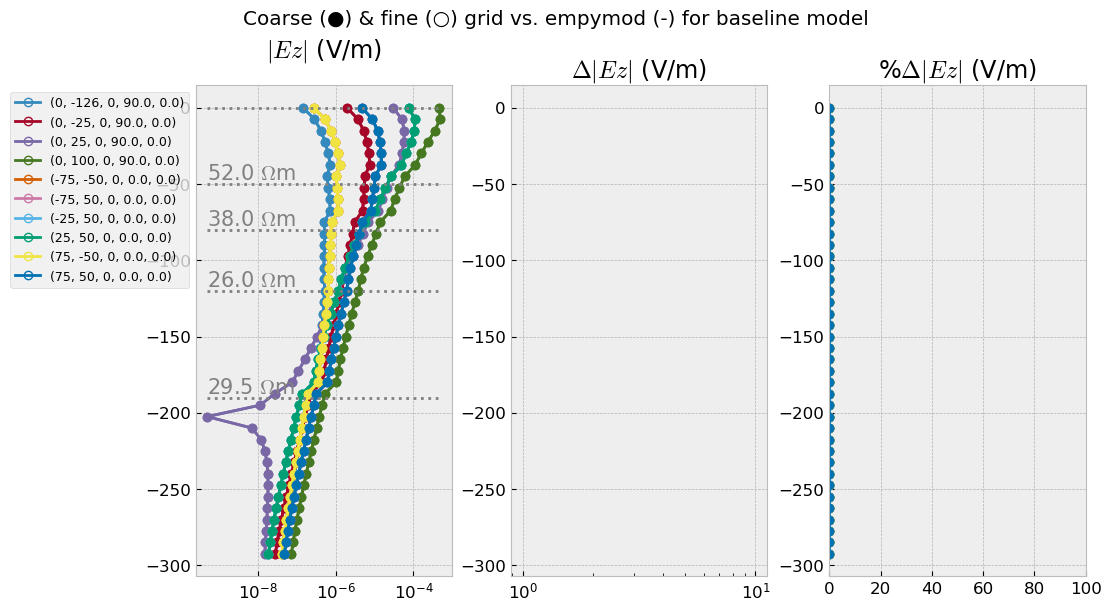

In [66]:
# Plot differences only

src_nrs = np.arange(len(src_coords))

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

fig3.suptitle("Coarse (●) & fine (○) grid vs. empymod (-) for baseline model")
plt.rcParams["font.size"] = 12

ax31.set_title('$|Ez|$ (V/m)')
ax32.set_title('$\\Delta |Ez|$ (V/m)')
ax33.set_title('%$\\Delta |Ez|$ (V/m)')

for src_nr in src_nrs:

    c_base = simulation2.data.synthetic[src_nr,:,0] #coarse
    f_base = simulation.data.synthetic[src_nr,:,0] #fine
    a_base = empymod_base_list[src_nr] #analytic

    ax31.plot(np.abs(c_base), -offsets, 'C'+str(src_nr), marker='o', fillstyle= 'full', linewidth=2)
    ax31.plot(np.abs(f_base), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length
    #ax31.plot(a_base.amp(), -offsets, 'C'+str(src_nr), '--', linewidth=2) # scale your emg3d amplitues by the source length
        
    ax32.plot(np.abs(np.abs(c_base)-np.abs(f_base)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='full', linewidth=2)
    #ax32.plot(np.abs(np.abs(f_base)-a_base.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)

    ax33.plot(100*np.abs((np.abs(c_base)-np.abs(f_base))/np.abs(f_base)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='full', linewidth=2)
    #ax33.plot(100*np.abs((np.abs(f_base)-a_base.amp())/a_base.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 100])

ax31.set_xscale('log')
ax32.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

In [50]:
print(np.shape(f_base), np.shape(a_base))

(40, 1) (40,)


### Forward modelling - creating simulated data

Code is based on sensitivity gradient notebook v1_7

We create a simulation class with the true model data + noise as observed data
This is all computed using the fine grid to create accuracy and prevent inverse crime

In [39]:
# Parameterize the noise to be added

noise_floor = 1e-13
relative_error = 0.05
mean_noise = 0.0

In [36]:
#We don't include noise yet as we compute it ourselves later

survey = emg3d.surveys.Survey(
    name='Survey forward-modelling',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)

In [38]:
# Simulate with the true model to create the observed data free of noise

simulation = emg3d.simulations.Simulation(
            name='Simulation forward-modelling',    # A name for this simulation
            survey=survey,        # Our survey instance
            model=fmodel_target_sigma,          # The model
            gridding='same',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            #gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear" #Needed for correct computation of the gradient
        )

simulation.compute(observed=True)
#The simulation should now contain observed data (+noise), synthetic data (without noise) and standard deviation values
#The survey class is also updated with this information

Compute efields            0/7  [00:00]

KeyboardInterrupt: 

In [31]:
# Compute the noise and overwrite the data, based on empymod+pygimli testing

dobs = survey.data['synthetic']

# Add random white noise to dobs
std_dev_real = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.real)**2)
std_dev_imag = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.imag)**2)
noise_real = rng_real.normal(loc=0, scale=std_dev_real, size = dobs.shape)
noise_imag = rng_imag.normal(loc=0, scale=std_dev_imag, size = dobs.shape)
std_dev = std_dev_real + 1j*std_dev_imag
noise = noise_real + 1j*noise_imag
dobs += noise
dobs0 = dobs
noise0 = noise

# Overwrite values in survey
survey.data['observed'] = dobs
survey.standard_deviation = std_dev

### Inversion - defining the starting model

Now we create a simulation class with the true model data + noise as the observed data and the starting model data without noise as the synthetic data.

We use the coarse grid in all inversion-related steps, taking only the observed data values with us from fine grid computation

In [32]:
survey2 = emg3d.surveys.Survey(
    name='Survey to go into inversion',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    data=survey.data['observed'], # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)
survey2.standard_deviation = survey.standard_deviation

In [43]:
simulation2 = emg3d.simulations.Simulation(
            name='Simulation to go into inversion 3',    # A name for this simulation
            survey=survey2,        # Our survey instance
            model=cmodel_base_sigma,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear", #Needed for correct computation of the gradient
            tqdm_opts = False #To switch-off progress bar during inversion
        )

simulation2.compute(observed=False)
#We don't put observed=True in this case because this will overwrite the observed data saved inside the survey

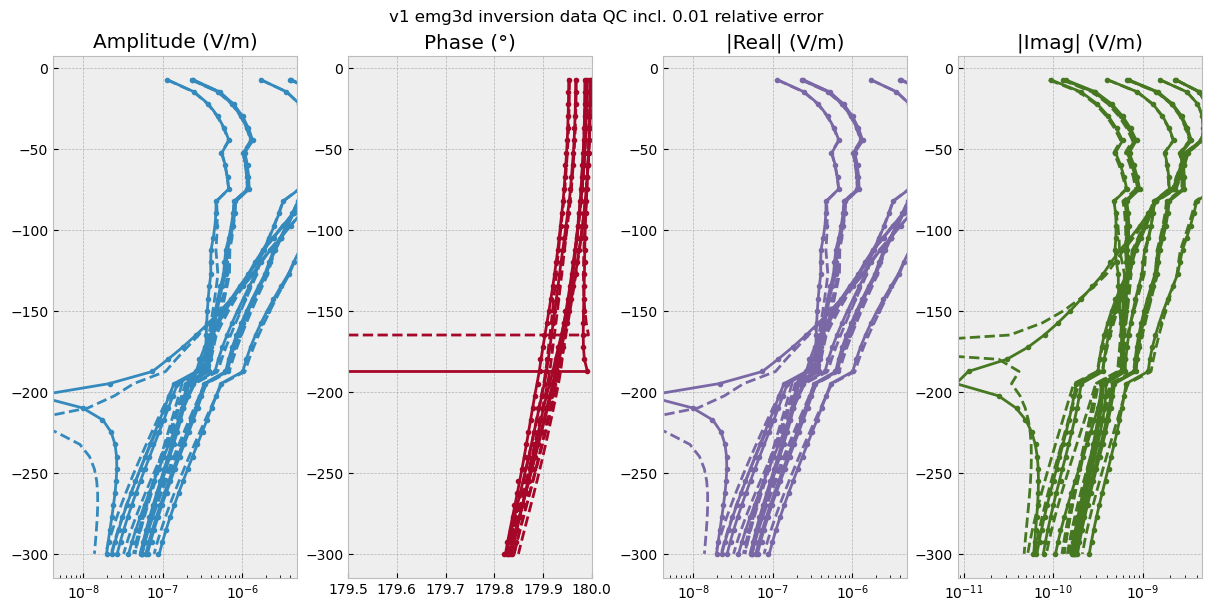

In [ ]:
# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]

for src_nr in np.arange(len(src_coords)):

    # QC data
    dobs = np.array(dobs0)[src_nr,:,0]
    noise = np.array(noise0)[src_nr,:,0]
    dhalf = np.array(survey2.data['synthetic'])[src_nr,:,0]
    

    #plt.locator_params(axis='x', nbins=3)

    #Plot measured data
    labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
    data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
    data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
    data_half = [np.abs(dhalf), np.angle(dhalf,deg=True), abs(dhalf.real), abs(dhalf.imag)]
    fig.suptitle("v1 emg3d inversion data QC incl. "+str(relative_error)+" relative error")
    for j in np.arange(len(labels)):
        ax = axes[j]
        ax.set_title(labels[j])
        ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - obs no noise")
        ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - observed")
        ax.plot(data_half[j][:], rec_coords[2], 'C'+str(j)+'--', label=f"{frequency: 2.1f} Hz - starting")
        #ax.legend(loc='upper left')
        ax.set_xscale('log')
        xmin, xmax = ax.get_xlim()
        ax.set_xlim([xmin*0.8, xmax*1.2])
        
    ax3.set_xscale('linear')
    ax3.set_xlim([179.5, 180])
    #The noise looks very acceptable

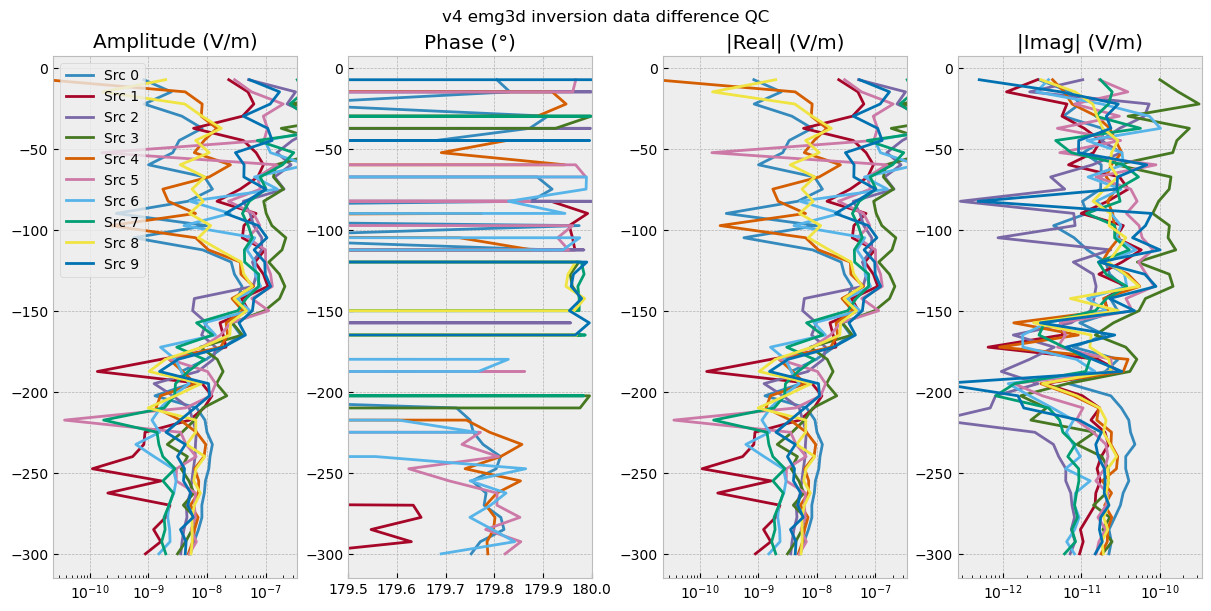

In [ ]:
# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]

for src_nr in np.arange(len(src_coords)):

    # QC difference
    diff = np.array(dobs0)[src_nr,:,0]-np.array(survey2.data['synthetic'])[src_nr,:,0]

    #plt.locator_params(axis='x', nbins=3)

    #Plot measured data
    labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
    p_diff = [np.abs(diff), np.angle(diff,deg=True), abs(diff.real), abs(diff.imag)]
    fig.suptitle("v4 emg3d inversion data difference QC")
    for j in np.arange(len(labels)):
        ax = axes[j]
        ax.set_title(labels[j])
        ax.plot(p_diff[j][:], rec_coords[2], label = f"Src "+str(src_nr))
        ax2.legend(loc='upper left')
        ax.set_xscale('log')
        xmin, xmax = ax.get_xlim()
        ax.set_xlim([xmin*0.8, xmax*1.2])
        
    ax3.set_xscale('linear')
    ax3.set_xlim([179.5, 180])

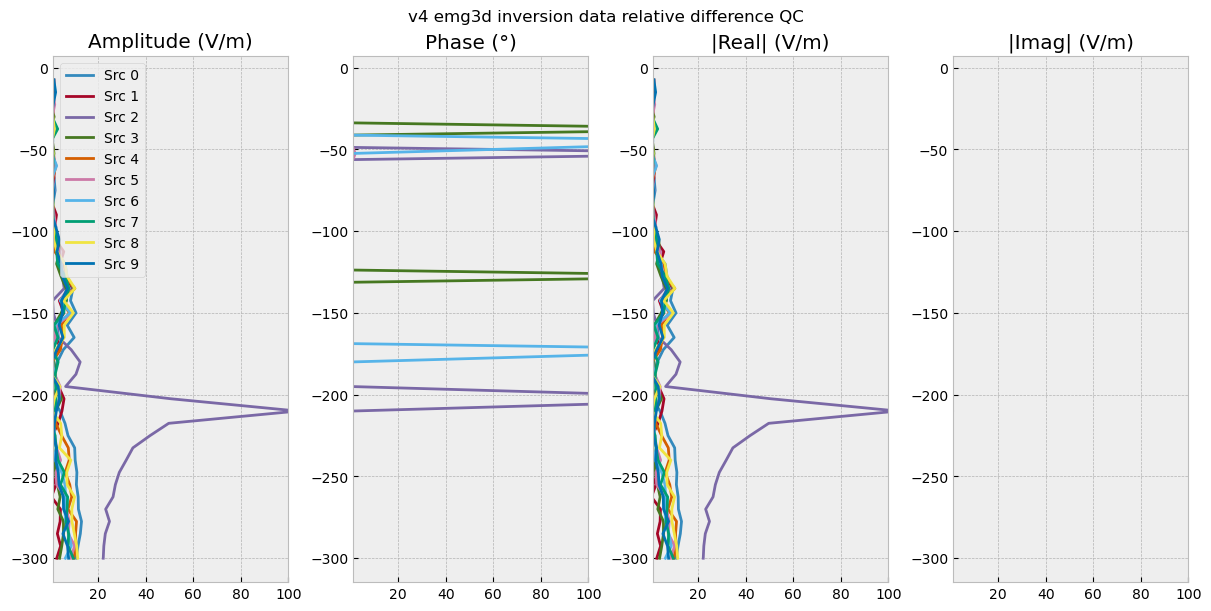

In [76]:
# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]

for src_nr in np.arange(len(src_coords)):

    # QC difference
    diff = 100*(np.array(dobs0)[src_nr,:,0]-np.array(survey2.data['synthetic'])[src_nr,:,0])/np.array(survey2.data['synthetic'])[src_nr,:,0]

    #plt.locator_params(axis='x', nbins=3)

    #Plot measured data
    labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
    p_diff = [np.abs(diff), np.angle(diff,deg=True), abs(diff.real), abs(diff.imag)]
    fig.suptitle("v4 emg3d inversion data relative difference QC")
    for j in np.arange(len(labels)):
        ax = axes[j]
        ax.set_title(labels[j])
        ax.plot(p_diff[j][:], rec_coords[2], label = f"Src "+str(src_nr))
        ax2.legend(loc='upper left')
        #ax.set_xscale('log')
        #xmin, xmax = ax.get_xlim()
        #ax.set_xlim([xmin*0.8, xmax*1.2])
        ax.set_xlim([1e0,1e2])
        
    ax3.set_xscale('linear')
    #ax3.set_xlim([179.5, 180])
    #The noise looks very acceptable

## Define regions, instantiate Kernel and Inversion

We only invert for the value of the anomaly, not the location, by marking the region of the anomaly and using single=True in pyGIMLi's region manager

In [44]:
# Create markers to define the center region

# Find indeces of the center region
ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(cgrid, x_extent = 100, y_extent=100, zmin = z_min, zmax = z_max)

# Create region markers
markers = np.zeros(simulation2.model.shape, dtype=int)
markers[ix_min:ix_max+1, iy_min:iy_max+1, iz_min:iz_max+1] = 1 # Only center region is inverted for

[-99, -99, -189] [99, 99, -121]
x:  -97.50000000000777
y:  -97.49999999999955
z:  -187.49999999999397
x:  97.49999999999223
y:  97.50000000000045
z:  -122.49999999999397


In [45]:
print(np.shape(markers[ix_min:ix_max+1, iy_min:iy_max+1, iz_min:iz_max+1]))

(14, 14, 14)


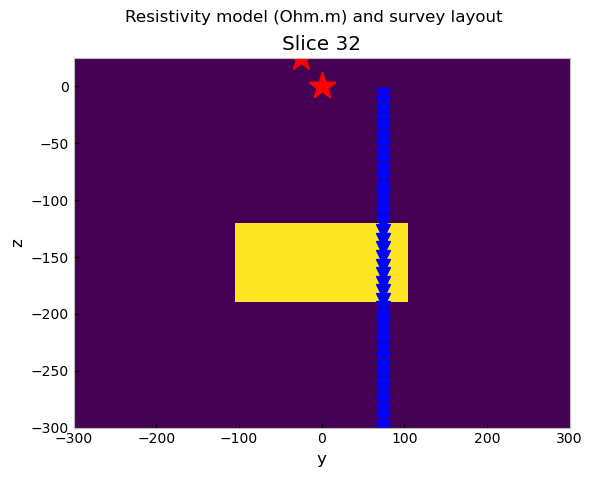

In [46]:
# QC the inversion region corresponds to the wanted region
# #Focus on the y,z plane
cgrid.plot_slice(
    markers,
    normal = 'X',
    #pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(src_coords[1], src_coords[2], 'r*', markersize = 20)
axs[1].grid(False)

In [47]:
# Instantiate the emg3d-kernel for pyGIMLi
fop = ipygimli.Kernel(simulation=simulation2, markers=markers, pgthreads=1)

# Instantiate the inversion and set some inversion parameters
INV = ipygimli.Inversion(fop=fop)
#INV.inv.setCGLSTolerance(1)  # is _absolute_, not _relative_
INV.inv.setMaxCGLSIter(10)

# Set the regions.
INV.fop.setRegionProperties(1, limits=(0.01, 2)) # Center region
INV.fop.setRegionProperties(0, background=True) # Background

## Run inversion

In [48]:
INV.run(
    #maxIter=2, # just to test
    lam=40,  # btw 1-100
    lambdaFactor=10,
    stopAtChi1=False,
    dPhi=5.0,
    #verbose=True,
    #debug=True,
    #startModel=model.property_x.ravel('F'),
    #isReference=True, 
)

04/10/26 - 21:59:13 - pyGIMLi - INFO - :: pyGIMLi(emg3d) START ::
04/10/26 - 22:04:25 - pyGIMLi - INFO - ===========================================================================
                                        it   F(m)         χ²          λ         ϕᵈ         ϕᵐ   ϕ=ϕᵈ+λϕᵐ   Δϕ (%)
                                       ---------------------------------------------------------------------------
04/10/26 - 22:04:25 - pyGIMLi - INFO -   0      1     1644.2       40.0  1.315e+06        0.0  1.315e+06     0.00
05/10/26 - 12:39:17 - pyGIMLi - INFO -   1     25       67.7       40.0    54175.2       66.1    56817.8    95.68
06/10/26 - 09:43:45 - pyGIMLi - INFO -   2     25       27.6      400.0    22058.6       50.8    42360.5    25.45
06/10/26 - 13:28:56 - pyGIMLi - INFO -   3     24       51.6     4000.0    41285.7       30.3   162320.5  -283.19
06/10/26 - 13:28:57 - pyGIMLi - INFO - :: pyGIMLi(emg3d) END   :: runtime = 1 day, 15:29:44


# Plots

In [49]:
# Load relevant inversion parameters saved through post_step (ipygimli functionality)

inv_data = h5py.File("Simulation to go into inversion 3.h5",'r')

phi_history = []
for i in np.arange(len(INV.modelHistory)):
    phi_history.append(int(np.array(inv_data['invinfo'][str(i)]['phi'])))

print(phi_history)

[1315360, 56817, 42360, 162320]


In [ ]:
print(inv_data.keys())

<KeysViewHDF5 ['_date', '_format', '_version', 'invinfo', 'simulation']>


Text(0.5, 1.0, 'Inversion information')

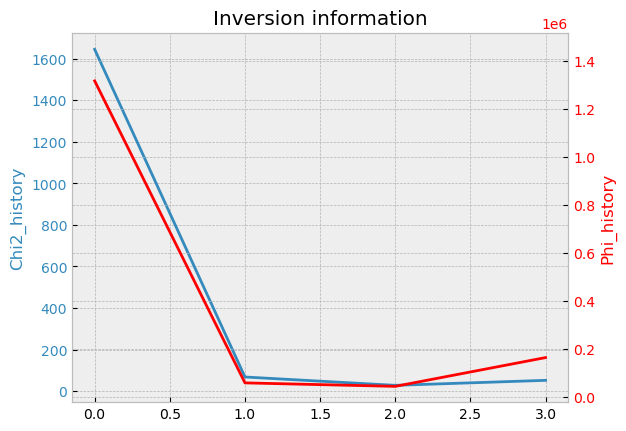

In [50]:
fig, ax = plt.subplots()

ax.plot(INV.chi2History)
ax.tick_params(axis='y', labelcolor='C0')
ax.set_ylabel('Chi2_history', color = 'C0')
ax2 = ax.twinx()
ax2.plot(phi_history, c = 'red')
ymin, ymax = ax2.get_ylim()
ax2.set_ylim([ymin*1.1, ymax*1.1])
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylabel('Phi_history', c='red')
ax.set_title('Inversion information')

In [51]:

center_index = point2_index_xyz(cgrid, )

fig, ax = plt.subplots()

ax.plot(1/np.array(INV.modelHistory), label='Inversion value')
ax.set_ylabel('Target resistivity')
ax.set_title('Inversion model value')
xmin, xmax = ax.get_xlim()
ax.hlines(y = res_target, xmin=xmin, xmax=xmax, color='C1', label= 'True model')
ax.legend()

NameError: name 'point2_index_xyz' is not defined

Text(0.5, 0.98, 'Resistivity models (Ohmm) per iteration')

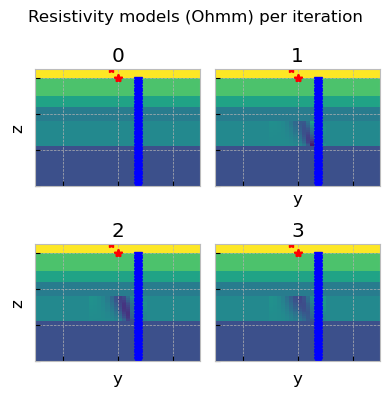

In [ ]:
#Code adapted from plot_models function in sampledata.py

sim_amount = len(INV.chi2History)
n_rows = 2
n_columns = 2
depth = 150
vmin = 10
vmax = 100

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)} #Normalize(vmin=vmin, vmax=vmax)}
# popts2 = {'edgecolors': 'grey', 'linewidth': 0.5, 'cmap': 'Spectral_r',
#           'norm': LogNorm(vmin=0.1, vmax=1000)}
opts = {'v_type': 'CC', 'normal': 'X', 'range_x': [-300, 300], 'range_y': [-300, 25],}

fig, axs = plt.subplots(n_rows, n_columns, figsize=(n_columns*2, n_rows*2), tight_layout=True, sharex = True, sharey = True)

for i in np.arange(sim_amount):
    ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
    m_it = 1/fop.model2emg3d(INV.modelHistory[i])

    # Plotting the model
    out = cgrid.plot_slice(m_it, ax=ax, pcolor_opts=popts, **opts)
    ax.set_title(str(i))
    ax.plot(rec_coords[1], rec_coords[2], 'bv')
    ax.plot(src_coords[1], src_coords[2], 'r*')
    if i%n_columns != 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])
        if i%n_columns == n_rows:
            plt.colorbar(out[0], ax=ax)#, fraction=.5, shrink=.8, aspect=30)
    
for i in np.arange(sim_amount-1-n_columns):
        ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
        ax.set_xlabel('')
        ax.set_xticklabels([])

    #for ax in axs.ravel():
    #    ax.axis('equal')
fig.suptitle('Resistivity models (Ohmm) per iteration')

In [ ]:
print(type(np.array(INV.fop.jacobian())))

: 

In [ ]:
#Check the jacobians

sim_amount = len(INV.chi2History)
n_rows = 2
n_columns = 2
depth = 150
vmin = 10
vmax = 100

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)} #Normalize(vmin=vmin, vmax=vmax)}
# popts2 = {'edgecolors': 'grey', 'linewidth': 0.5, 'cmap': 'Spectral_r',
#           'norm': LogNorm(vmin=0.1, vmax=1000)}
opts = {'v_type': 'CC', 'normal': 'X', 'range_x': [-300, 300], 'range_y': [-300, 25],}

fig, axs = plt.subplots(n_rows, n_columns, figsize=(n_columns*2, n_rows*2), tight_layout=True, sharex = True, sharey = True)

for i in np.arange(sim_amount):
    ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
    m_it = 1/fop.model2emg3d(INV.modelHistory[i])

    # Plotting the model
    out = cgrid.plot_slice(m_it, ax=ax, pcolor_opts=popts, **opts)
    ax.set_title(str(i))
    ax.plot(rec_coords[1], rec_coords[2], 'bv')
    ax.plot(src_coords[1], src_coords[2], 'r*')
    if i%n_columns != 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])
        if i%n_columns == n_rows:
            plt.colorbar(out[0], ax=ax)#, fraction=.5, shrink=.8, aspect=30)
    
for i in np.arange(sim_amount-1-n_columns):
        ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
        ax.set_xlabel('')
        ax.set_xticklabels([])

    #for ax in axs.ravel():
    #    ax.axis('equal')
fig.suptitle('Resistivity models (Ohmm) per iteration')

In [98]:
#inv_data['simulation'].keys()
inv_data['simulation']['survey']['data'].keys()

<KeysViewHDF5 ['observed', 'standard_deviation', 'it0', 'jvec', 'it1', 'it2', 'it3']>

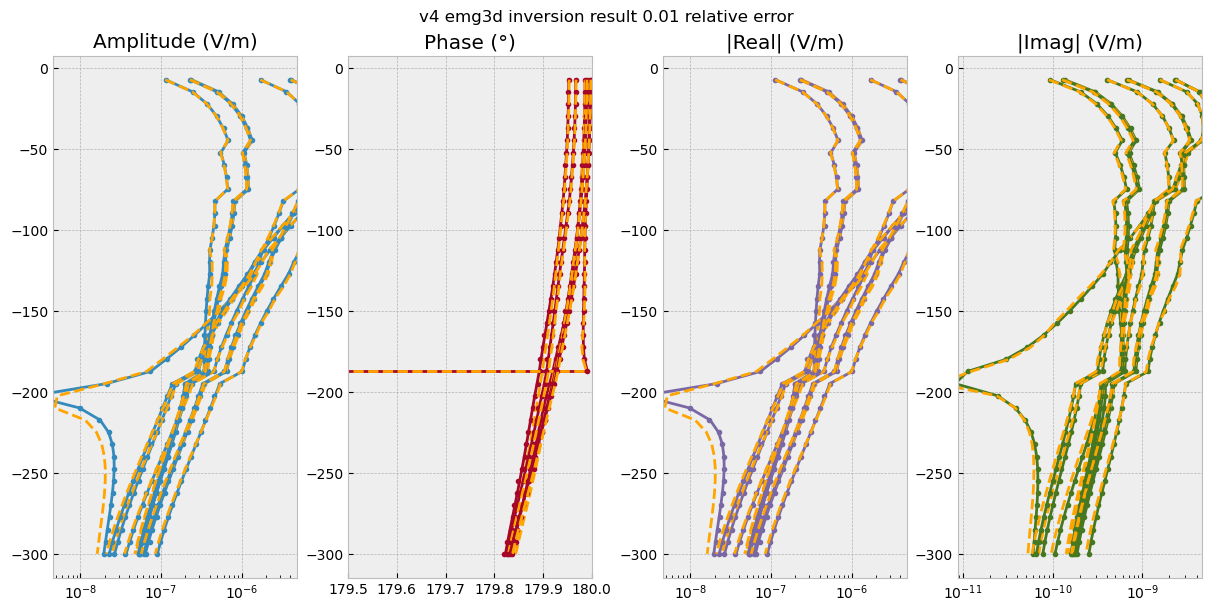

In [99]:
# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]

for src_nr in np.arange(len(src_coords)):
    # QC data
    dobs = np.array(dobs0)[src_nr,:,0]
    noise = np.array(noise0)[src_nr,:,0]
    response = inv_data['simulation']['survey']['data']['it3'][src_nr,:,0]

    #plt.locator_params(axis='x', nbins=3)

    #Plot measured data
    labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
    data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
    data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
    data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
    fig.suptitle("v4 emg3d inversion result "+str(relative_error)+" relative error")
    for j in np.arange(len(labels)):
        ax = axes[j]
        ax.set_title(labels[j])
        ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
        ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
        ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - fitted")
        #ax.legend(loc='upper left')
        ax.set_xscale('log')
        xmin, xmax = ax.get_xlim()
        ax.set_xlim([xmin*0.8, xmax*1.2])
        
    ax3.set_xscale('linear')
    ax3.set_xlim([179.5, 180])
    #The noise looks very acceptable

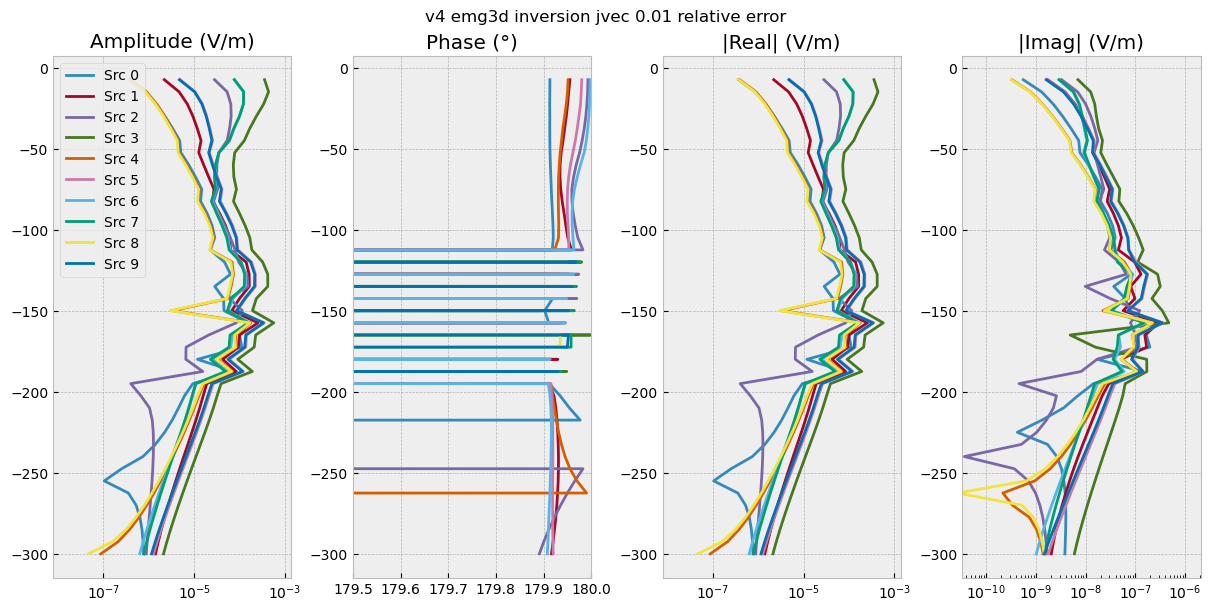

In [115]:
# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]

for src_nr in np.arange(len(src_coords)):
    # QC data
    diff = np.array(dobs0)[src_nr,:,0] - inv_data['simulation']['survey']['data']['jvec'][src_nr,:,0]#simulation2.survey.data.synthetic[src_nr,:,0]

    #plt.locator_params(axis='x', nbins=3)

    #Plot measured data
    labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
    p_diff = [np.abs(diff), np.angle(diff,deg=True), abs(diff.real), abs(diff.imag)]
    fig.suptitle("v4 emg3d inversion jvec "+str(relative_error)+" relative error")
    for j in np.arange(len(labels)):
        ax = axes[j]
        ax.set_title(labels[j])
        ax.plot(p_diff[j][:], rec_coords[2], label = "Src "+str(src_nr))
        ax2.legend(loc='upper left')
        ax.set_xscale('log')
        xmin, xmax = ax.get_xlim()
        ax.set_xlim([xmin*0.8, xmax*1.2])
        
    ax3.set_xscale('linear')
    ax3.set_xlim([179.5, 180])
    #The noise looks very acceptable

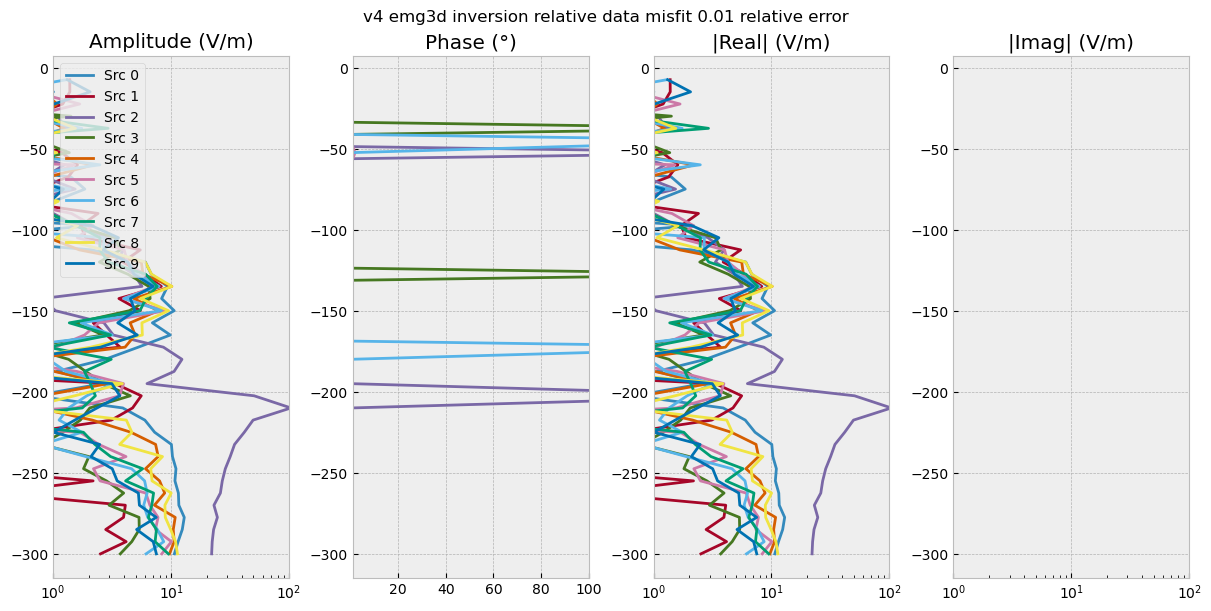

In [113]:

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]

for src_nr in np.arange(len(src_coords)):
    # QC data
    diff = 100*(np.array(dobs0)[src_nr,:,0] - inv_data['simulation']['survey']['data']['it3'][src_nr,:,0])/inv_data['simulation']['survey']['data']['it3'][src_nr,:,0]

    #plt.locator_params(axis='x', nbins=3)

    #Plot measured data
    labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
    p_diff = [np.abs(diff), np.angle(diff,deg=True), abs(diff.real), abs(diff.imag)]
    fig.suptitle("v4 emg3d inversion relative data misfit "+str(relative_error)+" relative error")
    for j in np.arange(len(labels)):
        ax = axes[j]
        ax.set_title(labels[j])
        ax.plot(p_diff[j][:], rec_coords[2], label = "Src "+str(src_nr))
        ax2.legend(loc='upper left')
        ax.set_xscale('log')
        #xmin, xmax = ax.get_xlim()
        #ax.set_xlim([xmin*0.8, xmax*1.2])
        ax.set_xlim([1, 100])
        
    ax3.set_xscale('linear')
    #ax3.set_xlim([179.5, 180])
    #The noise looks very acceptable

(179.5, 180.0)

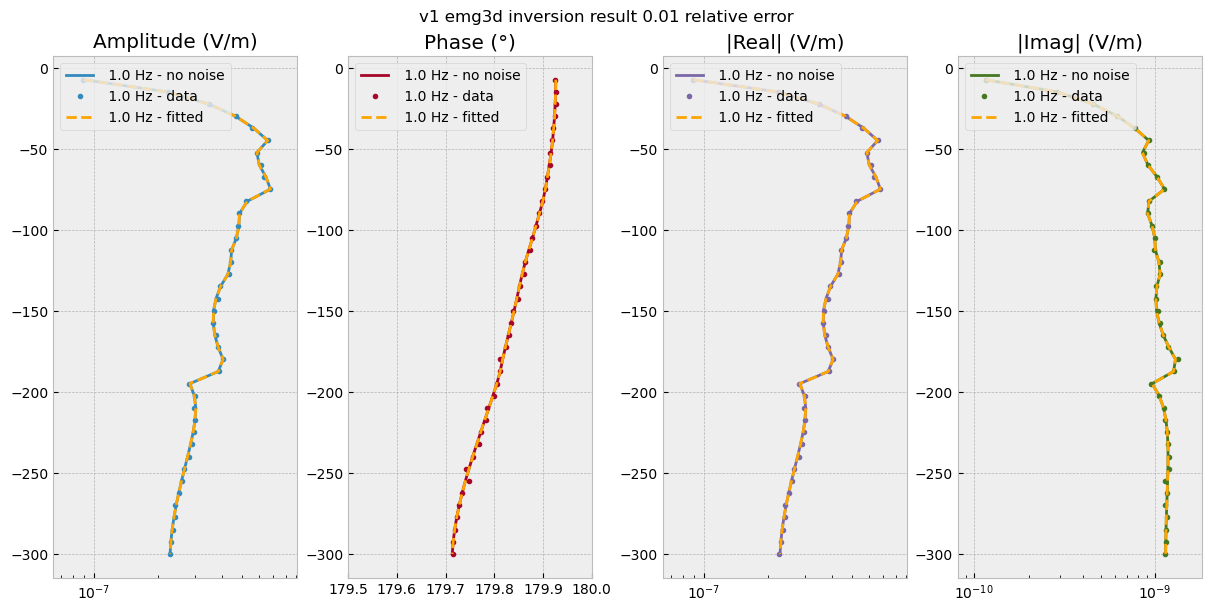

In [ ]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]
response = simulation2.survey.data.synthetic[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("v1 emg3d inversion result "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - fitted")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

(179.5, 180.0)

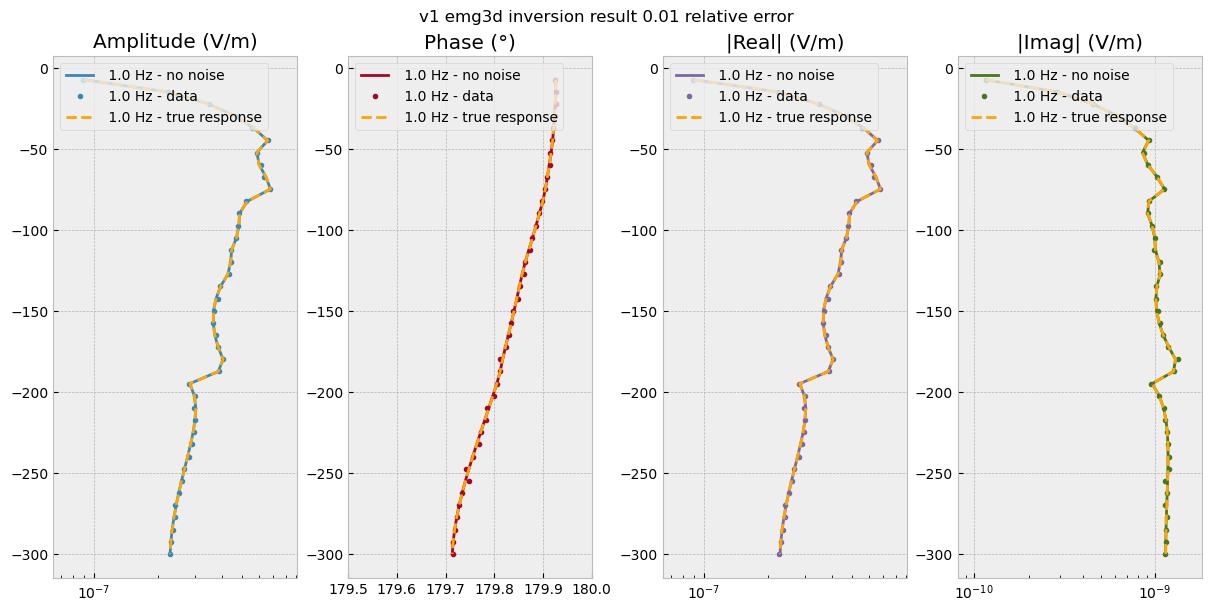

In [ ]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]

response = fop.data2emg3d(fop.response(fop.model2gimli(model_target2_conductivity.property_x)))[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("v1 emg3d inversion result "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - true response")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

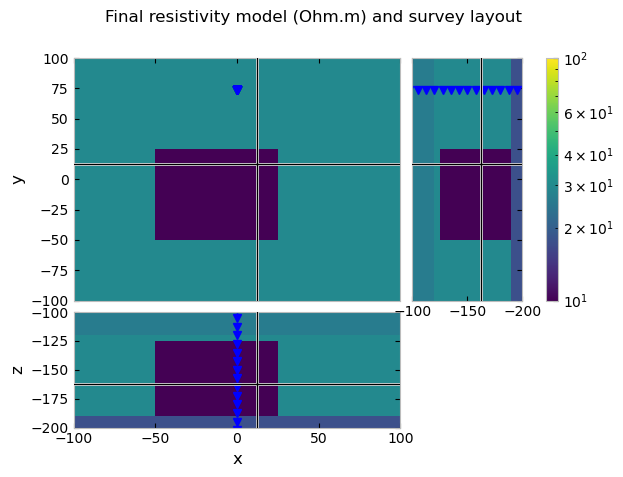

In [ ]:
#QC cube location
grid.plot_3d_slicer(
    1/fop.model2emg3d(INV.modelHistory[-1]),
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -100],
    zslice=-160,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Final resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

In [32]:
#Custom plume model

model1 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)
model2 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)
model3 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)

manual_plot_slice_3x(model1, model2, model3, y_extent=-100, zmin=-200, zmax=-100, size_y = 6.4, size_z = 4.8, vmin = 1e1, vmax = 1e2)

RuntimeError: ./core/src/matrix.h:466		GIMLI::Vector<ValueType2>& GIMLI::Matrix<ValueType>::rowRef(GIMLI::Index) [with ValueType = double; GIMLI::Index = long long unsigned int]  80 <= 80

In [33]:
A = INV.fop.jacobian()
jacobians = pg.sparseMatrix2Array(A)
#print(A)
#A*np.arange(1
#print(np.shape(np.sum(INV.fop.jacobian(), axis=0)))

NameError: name 'pg' is not defined

In [26]:
def crop_model(model3D, grid, x_slice = 0, y_extent=300, zmin=-250, zmax=0):

    #This method assumes cell_centers are the relevant parameters
    ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(grid, x_slice, y_extent, zmin, zmax, QC=True)

    #QC the bounds
    print('x position: ', grid.cell_centers_x[ix_max])
    print('y_bounds: ', grid.cell_centers_y[iy_min], ' , ', grid.cell_centers_y[iy_max])
    print('z_bounds: ', grid.cell_centers_z[iz_min], ' , ', grid.cell_centers_z[iz_max])

    # Crop Ez field array
    crop_model3D = model3D[ix_max, iy_min:iy_max, iz_min:iz_max]
    crop_model3D = np.flip(np.transpose(crop_model3D), axis=0)

    return crop_model3D

In [26]:
from sampledata import *

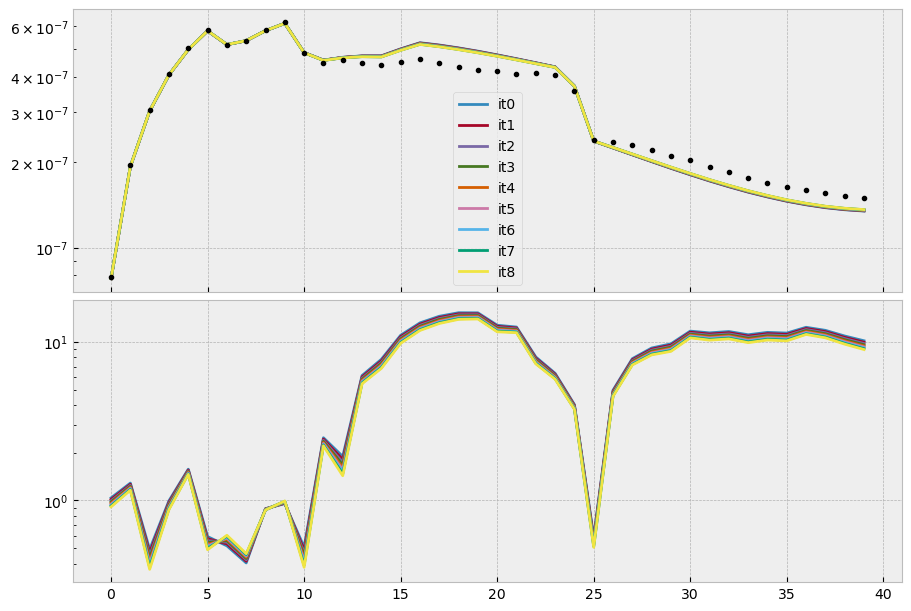

In [28]:
plot_responses(simulation2)

In [8]:
emg3d.Report()

--------------------------------------------------------------------------------
  Date: Tue Sep 10 17:08:40 2024 CEST

                OS : Linux (Ubuntu 22.04)
            CPU(s) : 16
           Machine : x86_64
      Architecture : 64bit
               RAM : 31.0 GiB
       Environment : Jupyter
       File system : ext4

  Python 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:36:13) [GCC
  12.3.0]

             numpy : 1.26.4
             scipy : 1.14.0
             numba : 0.59.1
             emg3d : 1.8.4.dev6+gd2f88de
           empymod : 2.3.1
            xarray : 2024.6.0
        discretize : 0.10.0
              h5py : 3.11.0
        matplotlib : 3.9.1
              tqdm : 4.66.4
           IPython : 8.26.0
           pygimli : 1.5.2
            pgcore : 1.5.0
--------------------------------------------------------------------------------